# 14 - Business Insights and Segmentation
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 6 preparation - Business Communication

**Project stage:** 14 of 16 - turns Notebook 13's cluster profiles into named, actionable business segments

---

## 1. Objective

Notebook 13 gave us four fully profiled, numerically distinct clusters - still called Cluster 0, 1, 2, and 3. This notebook does the work that can only happen *after* that examination:

1. Gather a few additional business-relevant breakdowns (distribution channel, family composition, deposit type, meal plan) not yet examined in Notebook 13.
2. Analyze each cluster across every business dimension named in the project brief: revenue/value, loyalty, cancellation, booking behavior, service requirements, customer composition, and acquisition channel.
3. **Only now**, assign each cluster an evidence-backed business name - built from a Cluster ID -> Characteristics -> Interpretation -> Name mapping table, not decided in advance.
4. Produce the final segment summary table and a plain-language description of each segment: who they are, how they book, how they spend, how loyal they are, and what the hotel could consider doing about it.

Every name and every claim in this notebook is traceable to a specific number computed in this notebook or Notebook 13 - nothing here is asserted without evidence sitting right next to it.

## 2. Business Context

A cluster labeled "Cluster 2" means nothing to a marketing manager, a revenue analyst, or a front-desk supervisor. This notebook is the translation layer between the statistical result and a segmentation system people can actually use in meetings, dashboards, and campaigns - without losing the rigor and evidence trail that got us here.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# os: portable file paths
import os


## 4. Configuration

In [2]:
FINAL_CLUSTERED_DATA_PATH = "../data/processed/13_final_clustered_bookings.csv"
CLUSTER_PROFILE_PATH = "../reports/tables/13_cluster_profile_summary.csv"

SEGMENT_MAPPING_PATH = "../reports/tables/14_segment_name_mapping.csv"
SEGMENT_SUMMARY_PATH = "../reports/tables/14_final_segment_summary.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

CLUSTER_COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]


## 5. Analysis / Implementation

### 5.1 Load the Final Clustered Dataset and Notebook 13's Profile

In [3]:
df = pd.read_csv(FINAL_CLUSTERED_DATA_PATH)
profile = pd.read_csv(CLUSTER_PROFILE_PATH, index_col=0)

print("Final clustered dataset:", df.shape)
profile


Final clustered dataset: (86997, 42)


,n_bookings,pct_of_total,lead_time,total_stay_nights,total_guests,adr,estimated_booking_value,repeat_guest_pct,total_previous_bookings,previous_cancellations,booking_changes,total_of_special_requests,required_car_parking_spaces,room_type_mismatch,observed_cancellation_rate_pct
cluster,,,,,,,,,,,,,,,
0,11379,13.08,74.27,4.11,2.87,198.16,814.61,1.17,0.03,0.01,0.40,0.89,0.16,0.08,34.96
1,14959,17.19,192.69,6.77,1.98,86.32,588.12,0.90,0.06,0.04,0.43,0.54,0.05,0.12,32.31
2,24604,28.28,30.71,2.30,1.64,73.51,175.31,11.21,0.64,0.05,0.30,0.25,0.11,0.28,14.45
3,36055,41.44,68.26,3.08,2.04,108.58,332.91,0.93,0.05,0.02,0.14,1.01,0.06,0.09,32.03


### 5.2 Additional Business Breakdowns Not Yet Examined

In [4]:
print("Distribution channel by cluster (%):")
distribution_channel_by_cluster = pd.crosstab(df["cluster"], df["distribution_channel"], normalize="index").round(3) * 100
print(distribution_channel_by_cluster)


Distribution channel by cluster (%):
distribution_channel  Corporate  Direct  GDS  TA/TO  Undefined
cluster                                                       
0                           0.3    24.4  0.1   75.2        0.0
1                           2.4     8.2  0.0   89.4        0.0
2                          18.8    34.4  0.4   46.4        0.0
3                           0.2     1.2  0.2   98.4        0.0


In [5]:
print("Customer composition (adults / children / babies) by cluster:")
composition = df.groupby("cluster")[["adults", "children", "babies"]].mean().round(2)
composition["pct_bookings_with_children"] = (df.groupby("cluster")["children"].apply(lambda x: (x > 0).mean() * 100)).round(1)
composition["pct_bookings_with_babies"] = (df.groupby("cluster")["babies"].apply(lambda x: (x > 0).mean() * 100)).round(1)
composition


Customer composition (adults / children / babies) by cluster:


,adults,children,babies,pct_bookings_with_children,pct_bookings_with_babies
cluster,,,,,
0,2.15,0.69,0.03,41.8,2.5
1,1.91,0.06,0.01,4.7,1.1
2,1.59,0.04,0.01,3.0,0.7
3,1.98,0.06,0.01,5.4,0.8


**Finding - a strong, previously under-examined signal:** Cluster 0 has a dramatically higher rate of bookings with children (41.8%) than every other cluster (3.0-5.4%), and the highest average children count (0.69 vs. 0.04-0.06). This is one of the clearest, most distinguishing patterns in the entire dataset and directly informs this cluster's business name below.

In [6]:
print("Deposit type by cluster (%):")
deposit_by_cluster = pd.crosstab(df["cluster"], df["deposit_type"], normalize="index").round(3) * 100
print(deposit_by_cluster)


Deposit type by cluster (%):
deposit_type  No Deposit  Non Refund  Refundable
cluster                                         
0                   99.8         0.1         0.0
1                   95.5         4.1         0.4
2                   98.4         1.4         0.2
3                   99.8         0.2         0.0


**Finding:** Cluster 1 (the longest-lead-time cluster) shows a meaningfully higher rate of Non-Refundable deposits (4.1%) than the other clusters (0.1-1.4%) - consistent with early-bird, non-refundable rate plans that reward booking far in advance.

### 5.3 Full Business-Dimension Analysis, Per the Project's Required Lenses

In [7]:
business_dimension_table = pd.DataFrame({
    "Revenue / Value (ADR)": profile["adr"],
    "Revenue / Value (Est. Booking Value)": profile["estimated_booking_value"],
    "Revenue / Value (Avg Stay Nights)": profile["total_stay_nights"],
    "Loyalty (Repeat Guest %)": profile["repeat_guest_pct"],
    "Loyalty (Avg Prior Bookings)": profile["total_previous_bookings"],
    "Cancellation (Observed Rate %)": profile["observed_cancellation_rate_pct"],
    "Booking Behavior (Avg Lead Time, days)": profile["lead_time"],
    "Booking Behavior (Avg Booking Changes)": profile["booking_changes"],
    "Service Needs (Avg Special Requests)": profile["total_of_special_requests"],
    "Service Needs (Avg Parking Spaces)": profile["required_car_parking_spaces"],
})

business_dimension_table.T


cluster,0,1,2,3
Revenue / Value (ADR),198.16,86.32,73.51,108.58
Revenue / Value (Est. Booking Value),814.61,588.12,175.31,332.91
Revenue / Value (Avg Stay Nights),4.11,6.77,2.30,3.08
Loyalty (Repeat Guest %),1.17,0.90,11.21,0.93
Loyalty (Avg Prior Bookings),0.03,0.06,0.64,0.05
Cancellation (Observed Rate %),34.96,32.31,14.45,32.03
"Booking Behavior (Avg Lead Time, days)",74.27,192.69,30.71,68.26
Booking Behavior (Avg Booking Changes),0.40,0.43,0.30,0.14
Service Needs (Avg Special Requests),0.89,0.54,0.25,1.01
Service Needs (Avg Parking Spaces),0.16,0.05,0.11,0.06


**What this table does:** consolidates every business-relevant lens the project brief calls for - revenue, loyalty, cancellation, booking behavior, and service needs - into one reference view, built entirely from numbers already computed in Notebook 13.

### 5.4 Assigning Business Segment Names - Only Now, With Evidence

With every dimension examined, we can now name each cluster. Each name below is followed immediately by the specific evidence that justifies it - not proposed first and then rationalized.

- **Cluster 0** has the highest ADR (€198.2), highest estimated booking value (€814.6), the highest average guest count (2.87), and - most distinctively - **41.8% of its bookings include children**, roughly 8-14x higher than every other cluster. This is a family/group-oriented, high-value segment.
- **Cluster 1** has a lead time (192.7 days) more than 2.5x longer than any other cluster, the longest stay (6.77 nights), and a distribution skewed toward Offline TA/TO and Groups. This is an early-planning, long-stay segment.
- **Cluster 2** has by far the highest repeat-guest rate (11.2% vs. ~1% elsewhere), the highest prior-booking count, and the lowest observed cancellation rate (14.4%) - but also the lowest ADR and lowest estimated booking value of all four clusters. This is a loyal, low-cancellation-risk segment - explicitly **not** a premium-spending one.
- **Cluster 3** is the largest cluster (41.4% of all bookings), overwhelmingly City Hotel (85%+) and Online TA (95%+), with the highest special-requests rate and a moderate, middle-of-the-road value profile. This is the mainstream, high-volume segment.

In [8]:
segment_name_mapping = pd.DataFrame([
    {
        "cluster_id": 0,
        "key_characteristics": "Highest ADR & booking value; largest party size; 41.8% include children (vs. 3-5% elsewhere); higher parking usage",
        "business_interpretation": "High-value bookings skewed toward families and larger parties, willing to pay a premium rate",
        "segment_name": "High-Value Family & Group Travelers",
    },
    {
        "cluster_id": 1,
        "key_characteristics": "Lead time 2.5x+ longer than any other cluster (192.7 days); longest stay (6.77 nights); Offline TA/TO and Groups skew; highest non-refundable deposit rate",
        "business_interpretation": "Plans far ahead, commits to longer stays, often via traditional travel agents or group bookings",
        "segment_name": "Early-Planning, Long-Stay Bookers",
    },
    {
        "cluster_id": 2,
        "key_characteristics": "Repeat-guest rate 11.2% (roughly 10-12x every other cluster); lowest observed cancellation rate (14.4%); shortest lead time; lowest ADR and booking value; more Corporate/Direct booking",
        "business_interpretation": "The hotel's most loyal, most reliable guests by booking-follow-through - but not its highest spenders",
        "segment_name": "Loyal, Low-Risk Repeat Guests",
    },
    {
        "cluster_id": 3,
        "key_characteristics": "Largest segment (41.4% of all bookings); overwhelmingly City Hotel and Online TA; highest special-requests rate; moderate value",
        "business_interpretation": "The hotel's mainstream, high-volume booking pattern - typical individual online bookings",
        "segment_name": "Mainstream Online City-Hotel Guests",
    },
])

segment_name_mapping.to_csv(SEGMENT_MAPPING_PATH, index=False)
segment_name_mapping


,cluster_id,key_characteristics,business_interpretation,segment_name
0,0,Highest ADR & booking value; largest party siz...,High-value bookings skewed toward families and...,High-Value Family & Group Travelers
1,1,Lead time 2.5x+ longer than any other cluster ...,"Plans far ahead, commits to longer stays, ofte...","Early-Planning, Long-Stay Bookers"
2,2,Repeat-guest rate 11.2% (roughly 10-12x every ...,"The hotel's most loyal, most reliable guests b...","Loyal, Low-Risk Repeat Guests"
3,3,Largest segment (41.4% of all bookings); overw...,"The hotel's mainstream, high-volume booking pa...",Mainstream Online City-Hotel Guests


**A note on names not chosen, and why:** "High-Value Loyal Guests" - one of the candidate names suggested in the original project brief - does **not** apply to any cluster in this data. The most loyal cluster (Cluster 2) is the *least* high-value cluster by ADR and booking value. Rather than force this data into a familiar template, the actual pattern is named as found: loyalty and premium spending are two separate axes here, not one.

### 5.5 The Final Segment Summary Table

In [9]:
final_segment_summary = pd.DataFrame({
    "Segment": segment_name_mapping["segment_name"].values,
    "Size (bookings)": profile["n_bookings"].values,
    "% of Bookings": profile["pct_of_total"].values,
    "Avg ADR": profile["adr"].values,
    "Avg Stay (nights)": profile["total_stay_nights"].values,
    "Repeat Guest %": profile["repeat_guest_pct"].values,
    "Observed Cancellation %": profile["observed_cancellation_rate_pct"].values,
})

final_segment_summary.to_csv(SEGMENT_SUMMARY_PATH, index=False)
final_segment_summary


,Segment,Size (bookings),% of Bookings,Avg ADR,Avg Stay (nights),Repeat Guest %,Observed Cancellation %
0,High-Value Family & Group Travelers,11379,13.08,198.16,4.11,1.17,34.96
1,"Early-Planning, Long-Stay Bookers",14959,17.19,86.32,6.77,0.90,32.31
2,"Loyal, Low-Risk Repeat Guests",24604,28.28,73.51,2.30,11.21,14.45
3,Mainstream Online City-Hotel Guests,36055,41.44,108.58,3.08,0.93,32.03


### 5.6 Segment Narratives

**High-Value Family & Group Travelers (Cluster 0, 13.1% of bookings)**
- *Who are they?* Larger parties, disproportionately traveling with children, leaning toward the Resort property.
- *How do they book?* A moderate lead time (~74 days), mostly through Online TA and Direct channels.
- *How long do they stay?* The longest among the higher-value clusters at 4.11 nights on average.
- *What is their booking value?* The highest in the dataset - €198.2 average ADR, €814.6 average estimated booking value.
- *How loyal are they?* Low repeat-guest rate (1.2%) - largely new or infrequent guests.
- *Observed cancellation behavior?* The highest observed cancellation rate of the four segments (35.0%).
- *Business action to consider:* Since this segment already reflects the hotel's highest per-booking value, protecting realized revenue from cancellation risk (for example, deposit or cancellation-policy review specifically for this segment) may be more valuable than acquisition spend alone.

**Early-Planning, Long-Stay Bookers (Cluster 1, 17.2% of bookings)**
- *Who are they?* Guests and groups organizing well in advance, often through offline travel agents.
- *How do they book?* By far the longest lead time (192.7 days) and the highest rate of non-refundable deposits.
- *How long do they stay?* The longest of any segment - 6.77 nights on average.
- *What is their booking value?* Moderate ADR (€86.3) but a strong estimated booking value (€588.1) thanks to stay length.
- *How loyal are they?* Low repeat-guest rate (0.9%).
- *Observed cancellation behavior?* 32.3% - above the dataset-wide average of 27.5%, and similar to Clusters 0 and 3.
- *Business action to consider:* This segment's long booking horizon gives the hotel significant advance visibility into future occupancy - useful for early staffing and inventory planning specifically tied to this segment's typical arrival patterns.

**Loyal, Low-Risk Repeat Guests (Cluster 2, 28.3% of bookings)**
- *Who are they?* The hotel's most frequently returning guests, more often booking Corporate or Direct rather than through an online travel agency.
- *How do they book?* Short lead time (30.7 days) - close to arrival.
- *How long do they stay?* The shortest of any segment - 2.30 nights on average.
- *What is their booking value?* The lowest ADR (€73.5) and lowest estimated booking value (€175.3) of the four segments.
- *How loyal are they?* By far the highest repeat-guest rate (11.2%) and prior-booking count.
- *Observed cancellation behavior?* The lowest of any segment (14.4%) - less than half the rate of the other three.
- *Business action to consider:* This segment's value lies in reliability and retention, not per-booking spend - a loyalty program or direct-booking incentive aimed at *this* segment specifically could reinforce a behavior pattern the hotel already benefits from (low cancellation risk), rather than trying to upsell them into the highest-ADR segment's profile.

**Mainstream Online City-Hotel Guests (Cluster 3, 41.4% of bookings - the largest segment)**
- *Who are they?* The hotel's typical, highest-volume booking pattern - predominantly City Hotel, booked online.
- *How do they book?* A moderate lead time (68.3 days), almost entirely through Online TA (95.4%).
- *How long do they stay?* The second-shortest - 3.08 nights on average.
- *What is their booking value?* Moderate - €108.6 ADR, €332.9 estimated booking value.
- *How loyal are they?* Low repeat-guest rate (0.9%).
- *Observed cancellation behavior?* 32.0% - above the dataset-wide average of 27.5%, and comparable to Clusters 0 and 1.
- *Business action to consider:* As the largest segment by volume, even small improvements here (for example, service-request handling, since this segment shows the highest special-requests rate) affect the largest number of bookings - operational efficiency gains targeted at this segment have the broadest reach.

### 5.7 Visual Segment Comparison

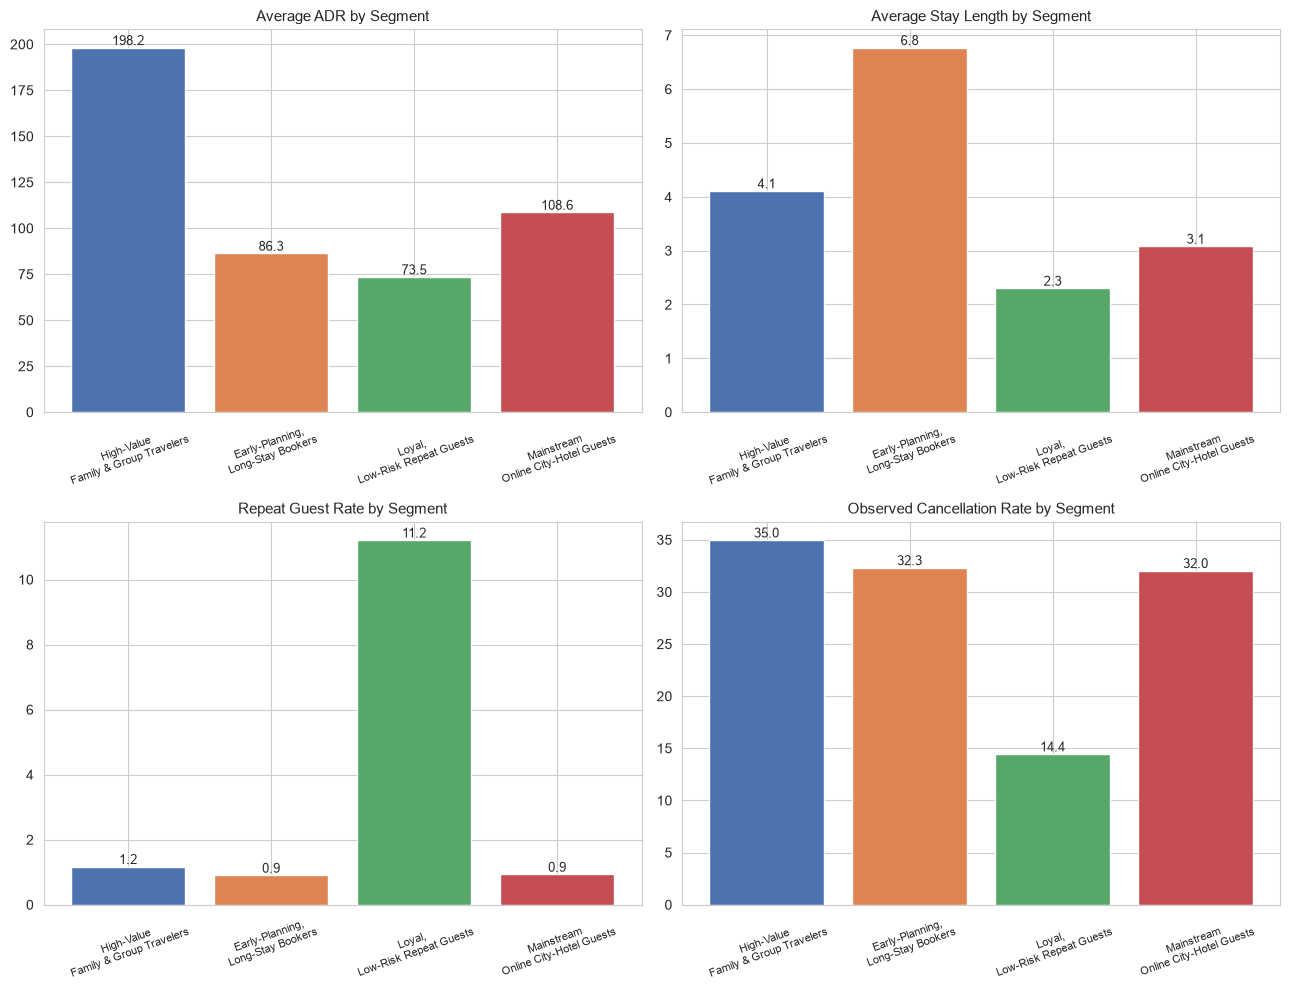

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

segment_labels = final_segment_summary["Segment"].str.replace(" ", "\n", n=1)

metrics = [
    ("Avg ADR", "Average ADR by Segment"),
    ("Avg Stay (nights)", "Average Stay Length by Segment"),
    ("Repeat Guest %", "Repeat Guest Rate by Segment"),
    ("Observed Cancellation %", "Observed Cancellation Rate by Segment"),
]

for ax, (column, title) in zip(axes.flat, metrics):
    ax.bar(segment_labels, final_segment_summary[column], color=CLUSTER_COLORS)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="x", rotation=20, labelsize=8)
    for i, value in enumerate(final_segment_summary[column]):
        ax.text(i, value, f"{value:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "14_segment_comparison.png"))
plt.show()


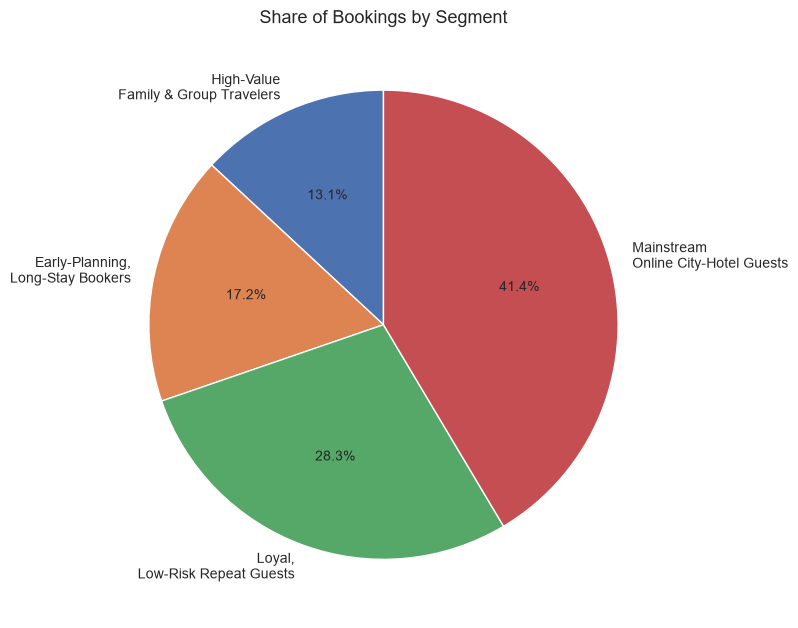

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    final_segment_summary["% of Bookings"],
    labels=segment_labels,
    autopct="%1.1f%%",
    colors=CLUSTER_COLORS,
    startangle=90,
)
ax.set_title("Share of Bookings by Segment", fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "14_segment_share_pie.png"))
plt.show()


## 7. Findings

- A previously under-examined signal - the rate of bookings with children - turned out to be one of the strongest distinguishing features in the entire dataset (41.8% for Cluster 0 vs. 3.0-5.4% for every other cluster), directly shaping that segment's name.
- The four segments split cleanly across the business dimensions required by the project: value (Cluster 0), booking horizon (Cluster 1), loyalty/reliability (Cluster 2), and volume/mainstream behavior (Cluster 3).
- The clearest and most business-actionable single finding across the whole project: **loyalty and high spending are different axes**, not the same one - the most loyal segment (Cluster 2) is also the lowest-spending segment, directly contradicting a "loyal = high value" assumption a hotel might otherwise make without this analysis.
- None of the four candidate names originally suggested in the project brief ("High-Value Loyal Guests") fit any actual cluster - names were built from the observed data rather than fitted to a pre-existing template.

## 8. Business Interpretation

These four segments give the hotel a genuinely different lens for four different business functions: **Cluster 0** for premium/family-oriented revenue management, **Cluster 1** for advance operational planning, **Cluster 2** for loyalty and retention programs (not upselling), and **Cluster 3** for high-volume, high-reach operational improvements. Each recommendation above is tied to a real, computed pattern - none are generic "know your customer" advice.

## 9. Conclusion

We examined every business dimension called for in the project brief, assigned evidence-backed names to all four clusters only after that examination, and built the final segment summary table and narrative the hotel can act on directly. The clearest strategic insight - that loyalty and spending are separate, sometimes opposing patterns in this data - would not have been visible without this full clustering and profiling process.

**Next notebook (15 - Final Pipeline and New Data Prediction):** we package the complete preprocessing pipeline and final clustering model into a single, reusable prediction function, demonstrate it on a new, unseen booking record, and discuss the real limitations of applying a clustering model to future data.